# Video Game Sales Analysis using Spark (RDD API)


## 1. Install PySpark and start a Spark session

In [ ]:
!pip install -q pyspark

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("VGSalesAnalysis").master("local[*]").getOrCreate()
sc = spark.sparkContext
print("Spark version:", spark.version)

Spark version: 4.0.4


## 2. Upload vgsales.csv
When the cell runs, click **Choose files** and select `vgsales.csv`.

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving vgsales.csv to vgsales.csv


## 3. Load the data as an RDD
The `csv` module is used so that game names containing commas inside quotes are parsed correctly.

In [ ]:
import csv
from operator import add

raw = sc.textFile("vgsales.csv")
header = raw.first()

def parse(line):
    try:
        row = next(csv.reader([line]))
        return [row] if len(row) == 11 else []
    except Exception:
        return []

def num(x):
    try:
        return float(x)
    except Exception:
        return 0.0

# columns: 0 Rank, 1 Name, 2 Platform, 3 Year, 4 Genre, 5 Publisher,
#          6 NA_Sales, 7 EU_Sales, 8 JP_Sales, 9 Other_Sales, 10 Global_Sales
rows = raw.filter(lambda l: l != header).flatMap(parse).cache()
print("Total game records:", rows.count())   # expect 16598

Total game records: 16598


## 4. Analyses (map / reduceByKey)

### 4.1 Total sales per genre (cross-check with the Hadoop job)

In [ ]:
genre_sales = (rows.map(lambda r: (r[4], num(r[10])))
                   .reduceByKey(add)
                   .sortBy(lambda x: -x[1]))
for g, s in genre_sales.collect():
    print(f"{g:15s} {s:10.2f}")

Action             1751.18
Sports             1330.93
Shooter            1037.37
Role-Playing        927.37
Platform            831.37
Misc                809.96
Racing              732.04
Fighting            448.91
Simulation          392.20
Puzzle              244.95
Adventure           239.04
Strategy            175.12


### 4.2 Total sales per platform

In [ ]:
platform_sales = (rows.map(lambda r: (r[2], num(r[10])))
                      .reduceByKey(add)
                      .sortBy(lambda x: -x[1]))
for p, s in platform_sales.take(10):
    print(f"{p:6s} {s:10.2f}")

PS2       1255.64
X360       979.96
PS3        957.84
Wii        926.71
DS         822.49
PS         730.66
GBA        318.50
PSP        296.28
PS4        278.10
PC         258.82


### 4.3 Sales by region

In [ ]:
totals = rows.map(lambda r: (num(r[6]), num(r[7]), num(r[8]), num(r[9]))) \
             .reduce(lambda a, b: tuple(x + y for x, y in zip(a, b)))
region_sales = list(zip(["North America", "Europe", "Japan", "Other"], totals))
for r, s in region_sales:
    print(f"{r:15s} {s:10.2f}")

North America      4392.95
Europe             2434.13
Japan              1291.02
Other               797.75


,Genre,North America,Europe,Japan,Other
4,Action,877.83,525.00,159.95,187.38
0,Sports,683.35,376.85,135.37,134.97
3,Shooter,582.60,313.27,38.28,102.69
7,Platform,447.05,201.63,130.77,51.59
9,Misc,410.24,215.98,107.76,75.32
1,Racing,359.42,238.39,56.69,77.27
2,Role-Playing,327.28,188.06,352.31,59.61
5,Fighting,223.59,101.32,87.35,36.68
10,Simulation,183.31,113.38,63.70,31.52
8,Puzzle,123.78,50.78,57.31,12.55


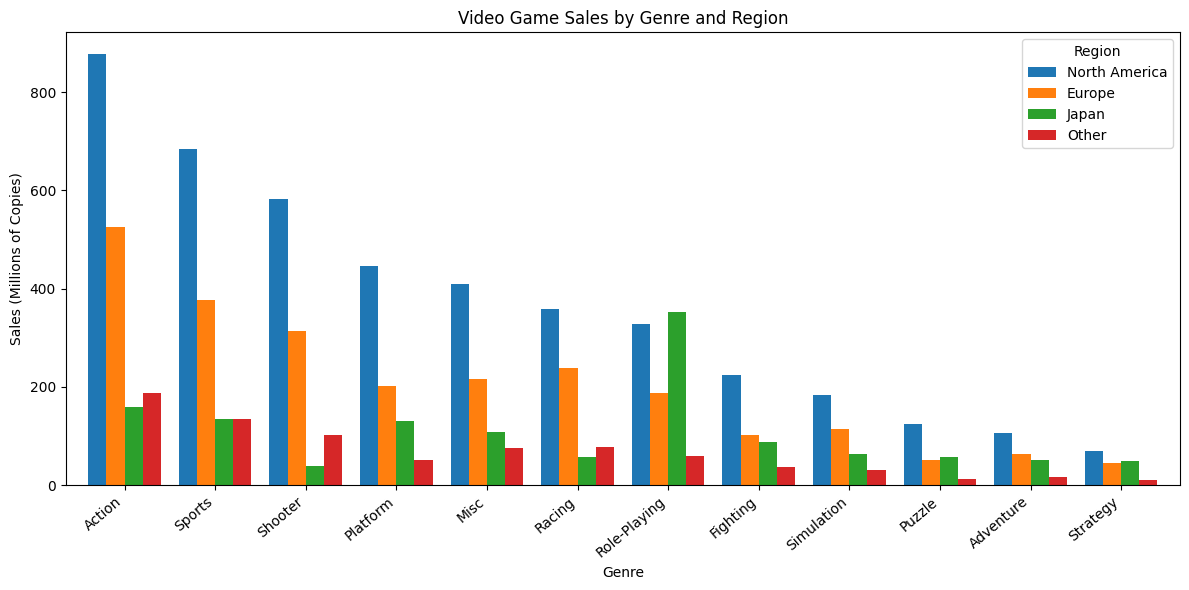

In [ ]:

# 4.6 Genre-wise sales by region using Spark RDD

from operator import add
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Aggregate regional sales for each genre
genre_region_sales = (
    rows.map(
        lambda r: (
            r[4],
            (
                num(r[6]),  # North America
                num(r[7]),  # Europe
                num(r[8]),  # Japan
                num(r[9])   # Other regions
            )
        )
    )
    .reduceByKey(
        lambda a, b: tuple(x + y for x, y in zip(a, b))
    )
    .collect()
)

# Convert Spark results into a Pandas DataFrame for plotting
genre_region_df = pd.DataFrame(
    [
        {
            "Genre": genre,
            "North America": values[0],
            "Europe": values[1],
            "Japan": values[2],
            "Other": values[3]
        }
        for genre, values in genre_region_sales
    ]
)

genre_region_df = genre_region_df.sort_values(
    "North America", ascending=False
)

display(genre_region_df.round(2))

# Grouped bar chart
ax = genre_region_df.set_index("Genre")[
    ["North America", "Europe", "Japan", "Other"]
].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Video Game Sales by Genre and Region")
ax.set_xlabel("Genre")
ax.set_ylabel("Sales (Millions of Copies)")
ax.legend(title="Region")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()

# Save graph
CHART_DIR = Path("results/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    CHART_DIR / "genre_region_sales.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# Export results for future use
genre_region_df.to_csv(
    "results/spark_genre_region_sales.csv",
    index=False
)


In [ ]:

# 4.7 Summary statistics using Spark RDD

# Count valid game records
total_records = rows.count()

# Calculate total global sales
total_global_sales = rows.map(
    lambda r: num(r[10])
).sum()

# Find the highest-selling individual game release
top_game = rows.map(
    lambda r: (r[1], num(r[10]))
).takeOrdered(
    1, key=lambda x: -x[1]
)[0]

# Find the top-selling platform
top_platform = rows.map(
    lambda r: (r[2], num(r[10]))
).reduceByKey(
    add
).takeOrdered(
    1, key=lambda x: -x[1]
)[0]

# Find the top-selling genre
top_genre = rows.map(
    lambda r: (r[4], num(r[10]))
).reduceByKey(
    add
).takeOrdered(
    1, key=lambda x: -x[1]
)[0]

# Display results
print("=" * 45)
print("VIDEO GAME SALES - SUMMARY STATISTICS")
print("=" * 45)
print(f"Total game records: {total_records:,}")
print(f"Total global sales: {total_global_sales:,.2f} million")
print(f"Top-selling game release: {top_game[0]}")
print(f"Sales of top game release: {top_game[1]:,.2f} million")
print(f"Top-selling platform: {top_platform[0]}")
print(f"Platform global sales: {top_platform[1]:,.2f} million")
print(f"Top-selling genre: {top_genre[0]}")
print(f"Genre global sales: {top_genre[1]:,.2f} million")
print("=" * 45)


VIDEO GAME SALES - SUMMARY STATISTICS
Total game records: 16,598
Total global sales: 8,920.44 million
Top-selling game release: Wii Sports
Sales of top game release: 82.74 million
Top-selling platform: PS2
Platform global sales: 1,255.64 million
Top-selling genre: Action
Genre global sales: 1,751.18 million


### 4.4 Total sales per release year

In [ ]:
year_sales = (rows.filter(lambda r: r[3].isdigit())
                  .map(lambda r: (int(r[3]), num(r[10])))
                  .reduceByKey(add)
                  .sortByKey())
print(year_sales.take(5))

[(1980, 11.379999999999999), (1981, 35.77), (1982, 28.859999999999996), (1983, 16.790000000000003), (1984, 50.360000000000014)]


### 4.5 Top 10 best-selling game releases and top 10 publishers

In [ ]:
top_games = rows.map(lambda r: (r[1], num(r[10]))).takeOrdered(10, key=lambda x: -x[1])

top_publishers = (rows.filter(lambda r: r[5] != "N/A")
                      .map(lambda r: (r[5], num(r[10])))
                      .reduceByKey(add)
                      .takeOrdered(10, key=lambda x: -x[1]))

print("Top games:")
for n, s in top_games:
    print(f"  {n:45s} {s:6.2f}")
print("Top publishers:")
for n, s in top_publishers:
    print(f"  {n:30s} {s:8.2f}")

Top games:
  Wii Sports                                     82.74
  Super Mario Bros.                              40.24
  Mario Kart Wii                                 35.82
  Wii Sports Resort                              33.00
  Pokemon Red/Pokemon Blue                       31.37
  Tetris                                         30.26
  New Super Mario Bros.                          30.01
  Wii Play                                       29.02
  New Super Mario Bros. Wii                      28.62
  Duck Hunt                                      28.31
Top publishers:
  Nintendo                        1786.56
  Electronic Arts                 1110.32
  Activision                       727.46
  Sony Computer Entertainment      607.50
  Ubisoft                          474.72
  Take-Two Interactive             399.54
  THQ                              340.77
  Konami Digital Entertainment     283.64
  Sega                             272.99
  Namco Bandai Games               254.09


## 5. Charts (Matplotlib)

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs("results/charts", exist_ok=True)

def bar_chart(data, title, xlabel, ylabel, filename, horizontal=False):
    labels = [d[0] for d in data]
    values = [d[1] for d in data]

    plt.figure(figsize=(8, 5))

    if horizontal:
        plt.barh(labels[::-1], values[::-1])
        plt.xlabel(ylabel)
        plt.ylabel(xlabel)
    else:
        plt.bar(labels, values)
        plt.xlabel(xlabel)
        plt.ylabel(ylabel)
        plt.xticks(rotation=45, ha="right")

    plt.title(title)
    plt.tight_layout()
    plt.savefig("results/charts/" + filename, dpi=150)
    plt.show()

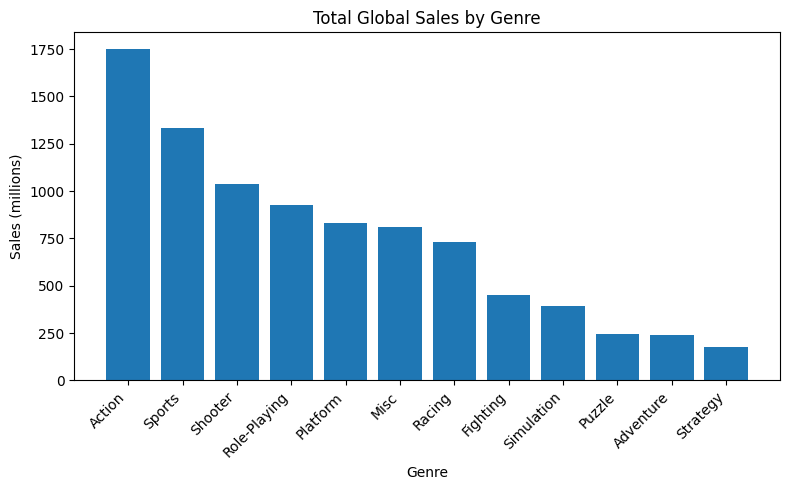

In [ ]:
bar_chart(
    genre_sales.collect(),
    "Total Global Sales by Genre",
    "Genre",
    "Sales (millions)",
    "genre_sales.png"
)

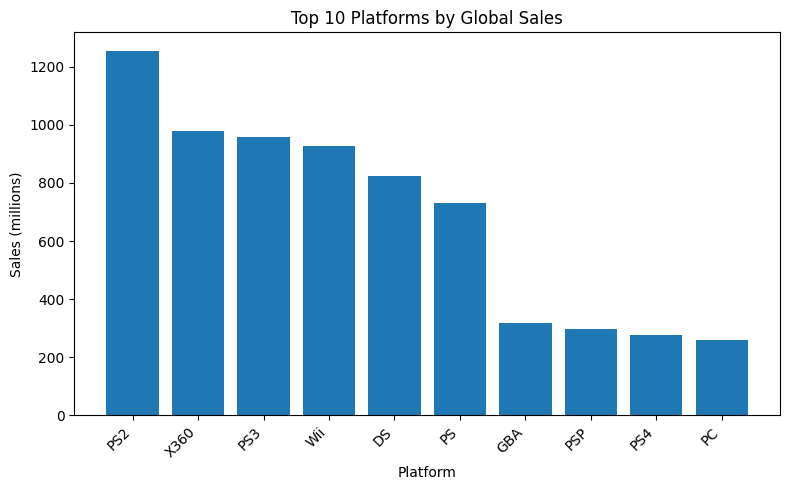

In [ ]:
bar_chart(
    platform_sales.take(10),
    "Top 10 Platforms by Global Sales",
    "Platform",
    "Sales (millions)",
    "platform_sales.png"
)

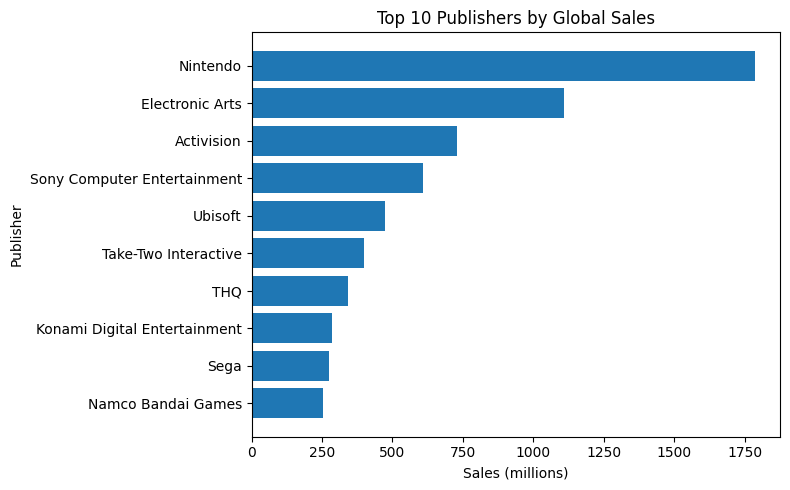

In [ ]:
bar_chart(
    top_publishers,
    "Top 10 Publishers by Global Sales",
    "Publisher",
    "Sales (millions)",
    "top_publishers.png",
    horizontal=True
)

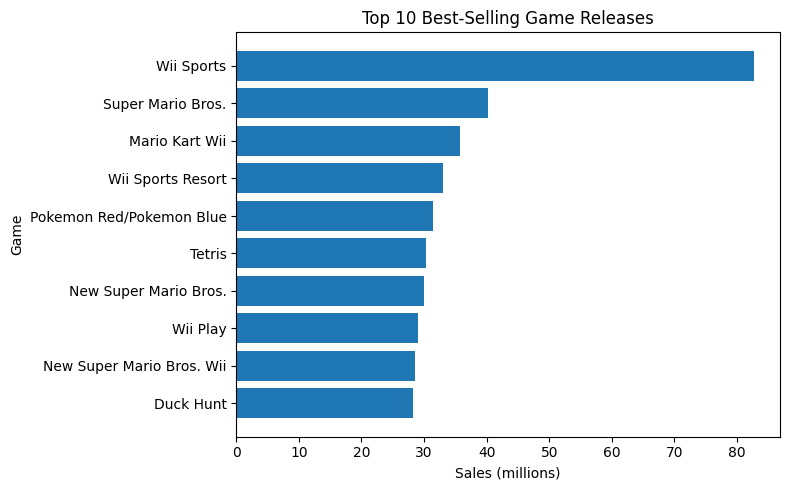

In [ ]:
bar_chart(
    top_games,
    "Top 10 Best-Selling Game Releases",
    "Game",
    "Sales (millions)",
    "top_games.png",
    horizontal=True
)

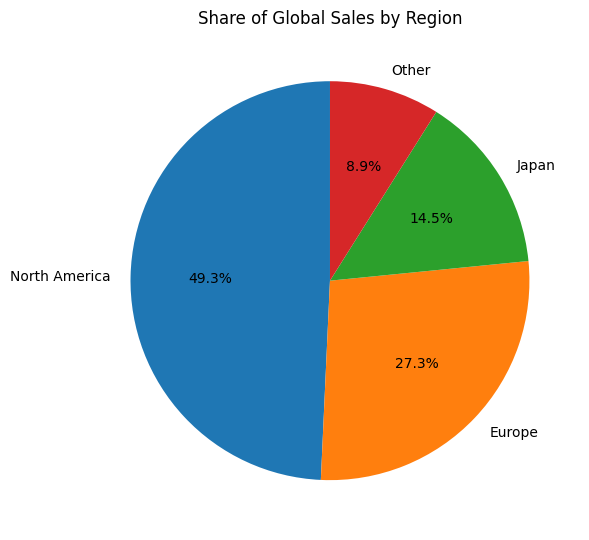

In [ ]:

# Pie chart: Share of Global Sales by Region

plt.figure(figsize=(6, 6))

plt.pie(
    [s for _, s in region_sales],
    labels=[r for r, _ in region_sales],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Share of Global Sales by Region")
plt.tight_layout()

plt.savefig("results/charts/region_sales.png", dpi=150)
plt.show()


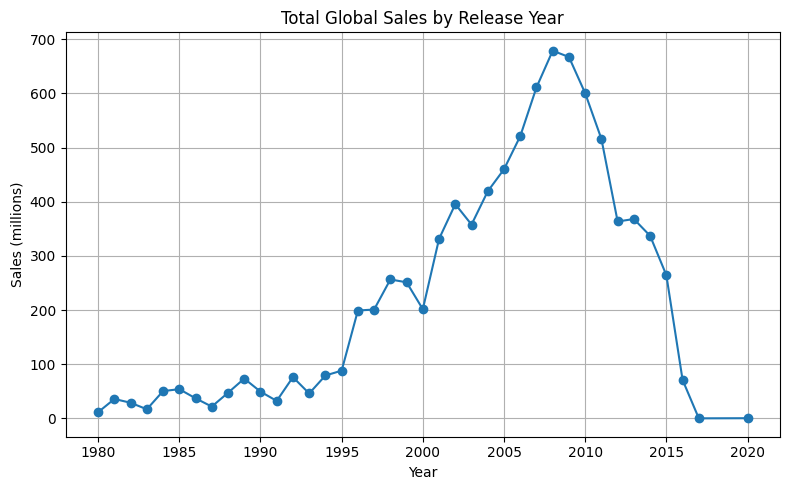

In [ ]:

# Line graph: Total Global Sales by Release Year

ys = sorted(year_sales.collect(), key=lambda x: x[0])

plt.figure(figsize=(8, 5))

plt.plot(
    [y for y, _ in ys],
    [s for _, s in ys],
    marker="o"
)

plt.title("Total Global Sales by Release Year")
plt.xlabel("Year")
plt.ylabel("Sales (millions)")
plt.grid(True)

plt.tight_layout()
plt.savefig("results/charts/year_sales.png", dpi=150)
plt.show()


## 6. Save the results and download them
The downloaded `results.zip` goes into `D:\hadoop-project\vgsales\results` for the dashboard and the report.

In [ ]:
import pandas as pd
import shutil
from google.colab import files

pd.DataFrame(genre_sales.collect(), columns=["genre", "sales"]).to_csv("results/spark_genre_sales.csv", index=False)
pd.DataFrame(platform_sales.collect(), columns=["platform", "sales"]).to_csv("results/spark_platform_sales.csv", index=False)
pd.DataFrame(region_sales, columns=["region", "sales"]).to_csv("results/spark_region_sales.csv", index=False)
pd.DataFrame(ys, columns=["year", "sales"]).to_csv("results/spark_year_sales.csv", index=False)
pd.DataFrame(top_games, columns=["game", "sales"]).to_csv("results/spark_top_games.csv", index=False)
pd.DataFrame(top_publishers, columns=["publisher", "sales"]).to_csv("results/spark_top_publishers.csv", index=False)

shutil.make_archive("results", "zip", "results")
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>